In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (7043, 21)
Missing Values: 0
Duplicate Rows: 0


In [4]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

# Calculate churn percentage
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Customer Churn Count:")
print(churn_counts)

print("\nCustomer Churn Percentage:")
print(churn_percentage.round(2))

print("\nOverall Churn Rate:",
      round((df["Churn"] == "Yes").mean() * 100, 2), "%")

Customer Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Overall Churn Rate: 26.54 %


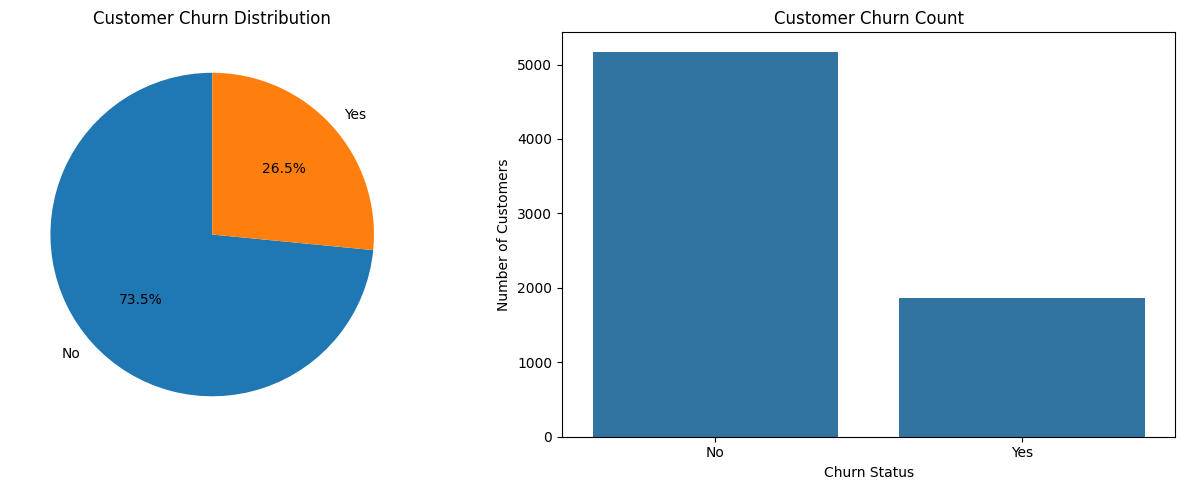

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie chart
churn_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    ax=axes[0]
)
axes[0].set_title("Customer Churn Distribution")
axes[0].set_ylabel("")

# Bar chart
sns.countplot(data=df, x="Churn", ax=axes[1])
axes[1].set_title("Customer Churn Count")
axes[1].set_xlabel("Churn Status")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [6]:
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"]
)

print("Churn Count by Gender:")
print(gender_churn)

print("\nChurn Percentage by Gender:")
print(
    pd.crosstab(
        df["gender"],
        df["Churn"],
        normalize="index"
    ).mul(100).round(2)
)

Churn Count by Gender:
Churn     No  Yes
gender           
Female  2549  939
Male    2625  930

Churn Percentage by Gender:
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16


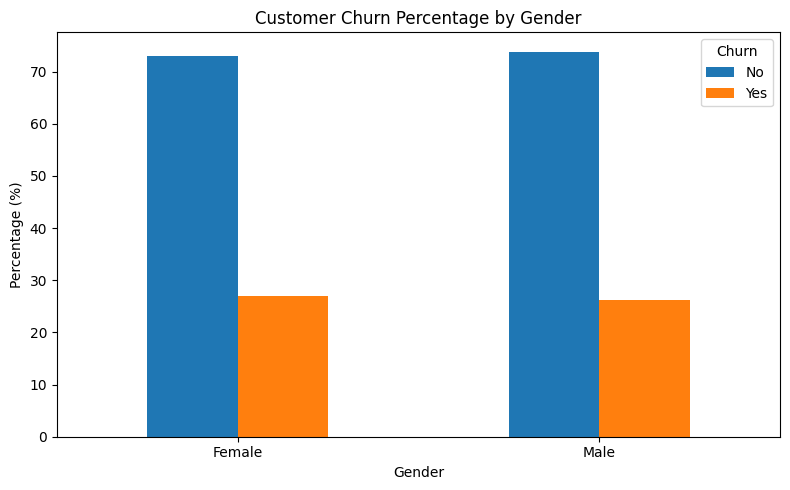

In [7]:
gender_churn_pct = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

gender_churn_pct.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Customer Churn Percentage by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [8]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"]
)

print("Churn Count by Senior Citizen:")
print(senior_churn)

print("\nChurn Percentage by Senior Citizen:")
print(
    pd.crosstab(
        df["SeniorCitizen"],
        df["Churn"],
        normalize="index"
    ).mul(100).round(2)
)

Churn Count by Senior Citizen:
Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476

Churn Percentage by Senior Citizen:
Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68


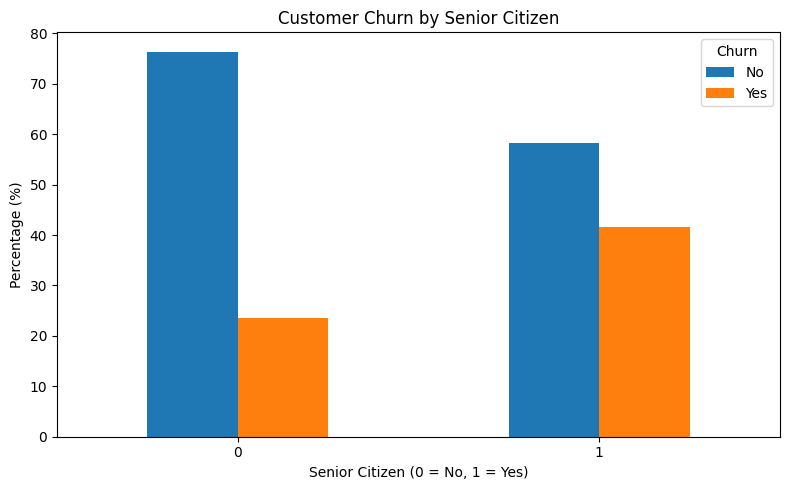

In [9]:
senior_churn_pct = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_churn_pct.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Customer Churn by Senior Citizen")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [10]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"]
)

print("Churn Count by Partner:")
print(partner_churn)

print("\nChurn Percentage by Partner:")
print(
    pd.crosstab(
        df["Partner"],
        df["Churn"],
        normalize="index"
    ).mul(100).round(2)
)

Churn Count by Partner:
Churn      No   Yes
Partner            
No       2441  1200
Yes      2733   669

Churn Percentage by Partner:
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66


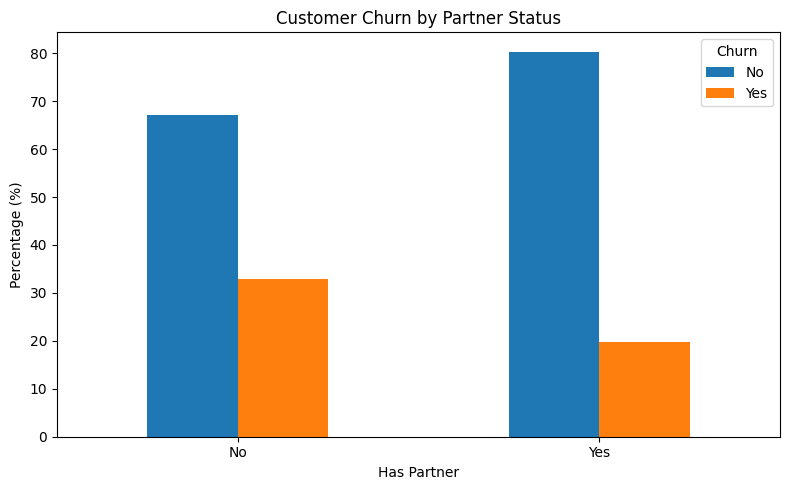

In [11]:
partner_churn_pct = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

partner_churn_pct.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Customer Churn by Partner Status")
plt.xlabel("Has Partner")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [12]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print("Churn Count by Contract:")
print(contract_churn)

print("\nChurn Percentage by Contract:")
print(
    pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    ).mul(100).round(2)
)

Churn Count by Contract:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48

Churn Percentage by Contract:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


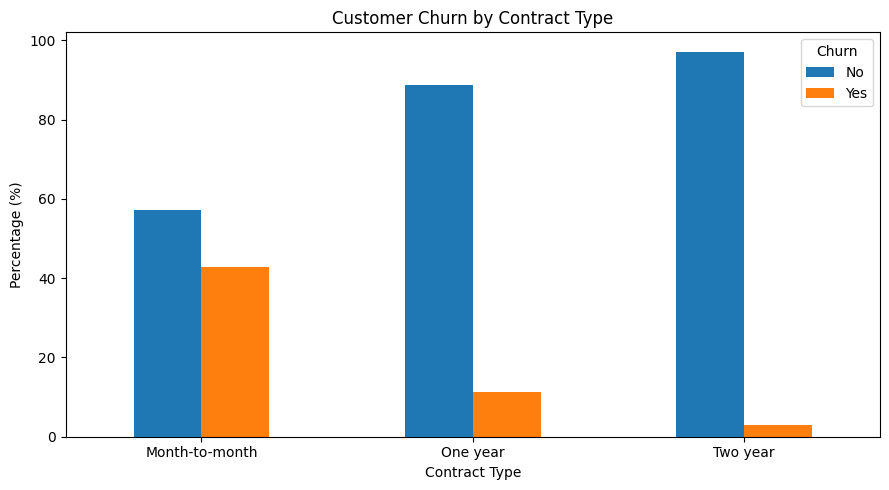

In [13]:
contract_churn_pct = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn_pct.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [14]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"]
)

print("Churn Count by Tenure:")
print(tenure_churn)

print("\nChurn Percentage by Tenure:")
print(
    pd.crosstab(
        df["TenureGroup"],
        df["Churn"],
        normalize="index"
    ).mul(100).round(2)
)

Churn Count by Tenure:
Churn           No   Yes
TenureGroup             
0-12 Months   1149  1037
13-24 Months   730   294
25-48 Months  1269   325
49-72 Months  2026   213

Churn Percentage by Tenure:
Churn            No    Yes
TenureGroup               
0-12 Months   52.56  47.44
13-24 Months  71.29  28.71
25-48 Months  79.61  20.39
49-72 Months  90.49   9.51


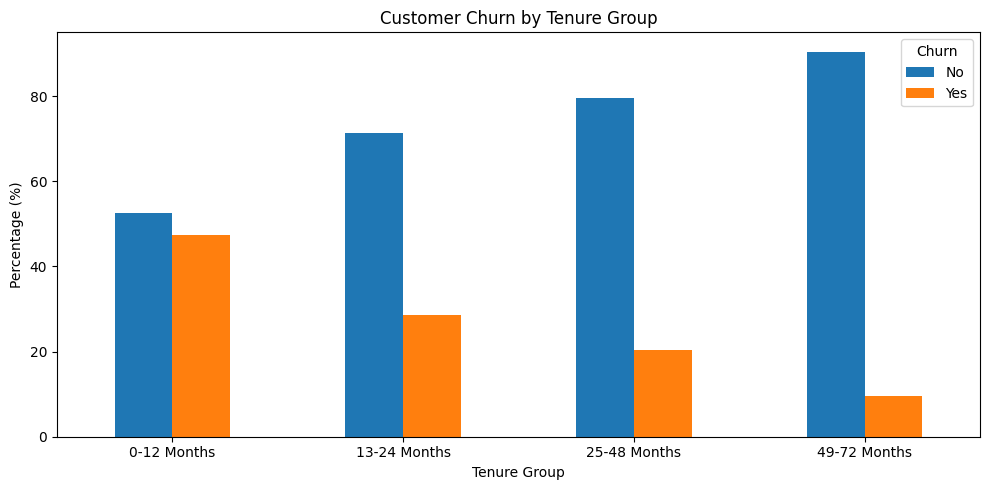

In [15]:
tenure_churn_pct = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn_pct.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Customer Churn by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [16]:
df["MonthlyChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 100, float("inf")],
    labels=["Low", "Medium", "High", "Very High"],
    include_lowest=True
)

monthly_churn = pd.crosstab(
    df["MonthlyChargeGroup"],
    df["Churn"]
)

print("Churn Count by Monthly Charges:")
print(monthly_churn)

print("\nChurn Percentage by Monthly Charges:")
print(
    pd.crosstab(
        df["MonthlyChargeGroup"],
        df["Churn"],
        normalize="index"
    ).mul(100).round(2)
)

Churn Count by Monthly Charges:
Churn                 No   Yes
MonthlyChargeGroup            
Low                 1546   189
Medium              1312   413
High                1667  1014
Very High            649   253

Churn Percentage by Monthly Charges:
Churn                  No    Yes
MonthlyChargeGroup              
Low                 89.11  10.89
Medium              76.06  23.94
High                62.18  37.82
Very High           71.95  28.05


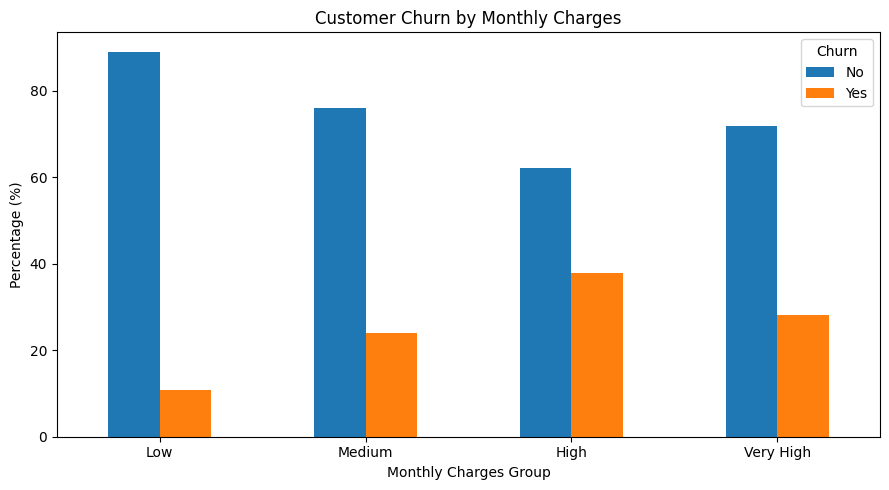

In [17]:
monthly_churn_pct = pd.crosstab(
    df["MonthlyChargeGroup"],
    df["Churn"],
    normalize="index"
) * 100

monthly_churn_pct.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Customer Churn by Monthly Charges")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Percentage (%)")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()